# SiliGuide — YOLO26n-seg Training Notebook

Trains a YOLO26n segmentation model on the Siling Labuyo leaf dataset using the Ultralytics framework.

- Auto-detects GPU and falls back to CPU if none is available.
- Dataset is assumed already split 70% train / 15% val / 15% test, in standard Ultralytics YOLO segmentation layout.
- Edit the CONFIGURATION cell below before running.

In [ ]:
import os
import sys
import random
import shutil
import subprocess
from pathlib import Path

# ============================================================
# DEPENDENCY CHECKER
# ============================================================
def ensure_installed(package_name, module_name=None):
    """Checks if a module is installed, and pip installs it if not."""
    if module_name is None:
        module_name = package_name
    try:
        __import__(module_name)
    except ImportError:
        print(f"[{package_name}] not found. Installing...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package_name])

# Verify and install required third-party packages
ensure_installed("numpy")
ensure_installed("pandas")
ensure_installed("pyyaml", "yaml")
ensure_installed("ultralytics")
ensure_installed("roboflow")

# Now that they are guaranteed to exist, run the actual imports
import numpy as np
import pandas as pd
import yaml
import torch
import ultralytics
from ultralytics import YOLO
from roboflow import Roboflow

# ============================================================
# ENVIRONMENT & HARDWARE SUMMARY / GPU CHECK
# ============================================================
print("=" * 60)
print("ENVIRONMENT & HARDWARE SUMMARY")
print("=" * 60)
print(f"Python      : {sys.version.split()[0]}")
print(f"PyTorch     : {torch.__version__}")
print(f"Ultralytics : {ultralytics.__version__}")
print(f"CUDA Ready  : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    gpu_vram = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    cuda_ver = torch.version.cuda
    print(f"GPU Device  : {gpu_name}")
    print(f"VRAM        : {gpu_vram:.2f} GB")
    print(f"CUDA Version: {cuda_ver}")
    DEVICE = 0  # first CUDA device — Ultralytics accepts an int index
else:
    print("No GPU detected — falling back to CPU.")
    DEVICE = "cpu"

print(f"Target Device: {DEVICE}")
print("=" * 60)

# ============================================================
# REPRODUCIBILITY
# ============================================================
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print(f"[REPRODUCIBILITY] Random seed locked to {SEED}.")

[ultralytics] not found. Installing...
[roboflow] not found. Installing...
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ENVIRONMENT & HARDWARE SUMMARY
Python      : 3.13.16
PyTorch     : 2.11.0+cu130
Ultralytics : 8.4.197
CUDA Ready  : True
GPU Device  : Tesla T4
VRAM        : 14.56 GB
CUDA Version: 13.0
Target Device: 0
[REPRODUCIBILITY] Random seed locked to 42.


## Configuration

Edit the paths and settings below. `DATASET_ROOT` must already contain the 70/15/15 train/val/test split
in standard Ultralytics layout:

```
DATASET_ROOT/
  images/train/*.jpg
  images/val/*.jpg
  images/test/*.jpg
  labels/train/*.txt
  labels/val/*.txt
  labels/test/*.txt
```

In [ ]:
# ============================================================
# CONFIGURATION
# ============================================================
import os
from roboflow import Roboflow
from google.colab import userdata
from google.colab import userdata, drive  # Imported drive

# Mount Google Drive to save weights permanently
drive.mount('/content/drive')

roboflowApiKey = userdata.get('roboflow')

# 1. Download dataset directly from Roboflow
# Replace with your actual API key, workspace, project, and version
rf = Roboflow(api_key=roboflowApiKey)
project = rf.workspace("test-akuzg").project("sili_with_null_fix4")
dataset = project.version(3).download("yolo26")

# 2. Dynamically set DATASET_ROOT to the downloaded dataset
DATASET_ROOT = os.path.join(dataset.location, "data.yaml")

# Load the model.
MODEL = "yolo26n-seg.pt"

# Where Ultralytics saves run outputs (weights, logs, curves, plots).
# Final save path ends up at: PROJECT_DIR/RUN_NAME/
PROJECT_DIR = "/content/drive/MyDrive/siliguide_yolo_colab/sili_with_null_fix_run1"
RUN_NAME = "siliguide_seg_colab_run2"

# Where to copy the final best.pt once training finishes.
FINAL_MODEL_SAVE_PATH = "/content/drive/MyDrive/siliguide_yolo_colab/SiliGuide_Weights/sili_with_null_fix_run1/best_yolo26_seg.pt"

# Ensure the destination directory exists before the training loop starts
Path(FINAL_MODEL_SAVE_PATH).parent.mkdir(parents=True, exist_ok=True)


Mounted at /content/drive
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to sili_with_null_fix4-3 in yolo26:: 100%|██████████| 5985/5985 [00:11<00:00, 510.55it/s] 


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Dataset Class & Instance Distribution

Scans `DATASET_ROOT` label files across `train`, `valid`, and `test` splits to verify:
- Total instance counts for each class
- Class balance and distribution across splits
- Total image counts and background (null/empty) images

DATASET: sili_with_null_fix4-3  |  TOTAL CLASSES: 4
 Class ID Class Name  Train Instances  Valid Instances  Test Instances  Total Instances Share (%)
        0    curling              806              201             106             1113     24.5%
        1    healthy              858              182             169             1209     26.7%
        2      spots              623              138             128              889     19.6%
        3  yellowing              926              191             207             1324     29.2%
---------------------------------------------------------------------------
Total Images   : 2990 (Train: 2093 | Valid: 449 | Test: 448)
Total Instances: 4535 (Train: 3213 | Valid: 712 | Test: 610)
Null/BG Images : 488 (Images with zero instances / background only)


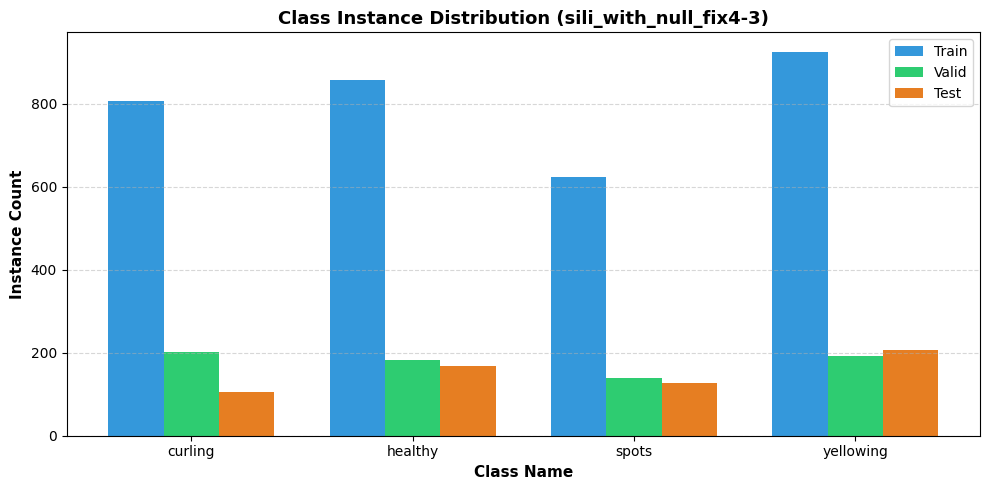

In [ ]:
# ============================================================
# DATASET CLASS INSTANCE COUNTER & DISTRIBUTION VISUALIZER
# ============================================================
from pathlib import Path
from collections import Counter
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Resolve dataset YAML and directory
yaml_path = Path(DATASET_ROOT) if 'DATASET_ROOT' in globals() else Path('sili_with_null_fix4.yolo26/data.yaml')
if not yaml_path.exists():
    raise FileNotFoundError(f"data.yaml not found at: {yaml_path.resolve()}")

with open(yaml_path, 'r', encoding='utf-8') as f:
    data_cfg = yaml.safe_load(f)

class_names = data_cfg.get('names', [])
if isinstance(class_names, dict):
    class_names = [class_names[i] for i in sorted(class_names.keys())]

dataset_root = yaml_path.parent
splits = ['train', 'valid', 'test']

# 2. Count instances per class in each split
split_counts = {s: Counter() for s in splits}
split_images = {s: 0 for s in splits}
split_null_images = {s: 0 for s in splits}

valid_img_exts = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

for s in splits:
    split_dir = dataset_root / s
    if not split_dir.exists() and s == 'valid':
        split_dir = dataset_root / 'val'

    lbl_dir = split_dir / 'labels'
    img_dir = split_dir / 'images'

    if img_dir.exists():
        split_images[s] = sum(1 for f in img_dir.iterdir() if f.suffix.lower() in valid_img_exts)

    if lbl_dir.exists():
        for lbl_file in lbl_dir.glob('*.txt'):
            with open(lbl_file, 'r', encoding='utf-8', errors='ignore') as f:
                lines = [line.strip() for line in f if line.strip()]
                if not lines:
                    split_null_images[s] += 1
                for line in lines:
                    parts = line.split()
                    if parts:
                        try:
                            cid = int(parts[0])
                            split_counts[s][cid] += 1
                        except ValueError:
                            pass

# 3. Build summary DataFrame
summary_rows = []
for cid, cname in enumerate(class_names):
    tr_c = split_counts['train'][cid]
    val_c = split_counts['valid'][cid]
    te_c = split_counts['test'][cid]
    tot = tr_c + val_c + te_c
    summary_rows.append({
        'Class ID': cid,
        'Class Name': cname,
        'Train Instances': tr_c,
        'Valid Instances': val_c,
        'Test Instances': te_c,
        'Total Instances': tot,
        'Share (%)': f"{(tot / max(1, sum(split_counts['train'].values()) + sum(split_counts['valid'].values()) + sum(split_counts['test'].values()))):.1%}"
    })

df_summary = pd.DataFrame(summary_rows)

print('=' * 75)
print(f"DATASET: {dataset_root.name}  |  TOTAL CLASSES: {len(class_names)}")
print('=' * 75)
print(df_summary.to_string(index=False))
print('-' * 75)
total_inst = sum(df_summary['Total Instances'])
total_imgs = sum(split_images.values())
total_null = sum(split_null_images.values())
print(f"Total Images   : {total_imgs} (Train: {split_images['train']} | Valid: {split_images['valid']} | Test: {split_images['test']})")
print(f"Total Instances: {total_inst} (Train: {sum(split_counts['train'].values())} | Valid: {sum(split_counts['valid'].values())} | Test: {sum(split_counts['test'].values())})")
print(f"Null/BG Images : {total_null} (Images with zero instances / background only)")
print('=' * 75)

# 4. Plot Class Distribution Bar Chart
x = np.arange(len(class_names))
width = 0.25

plt.figure(figsize=(10, 5), dpi=100)
plt.bar(x - width, [split_counts['train'][i] for i in range(len(class_names))], width, label='Train', color='#3498db')
plt.bar(x, [split_counts['valid'][i] for i in range(len(class_names))], width, label='Valid', color='#2ecc71')
plt.bar(x + width, [split_counts['test'][i] for i in range(len(class_names))], width, label='Test', color='#e67e22')

plt.xlabel('Class Name', fontweight='bold', fontsize=11)
plt.ylabel('Instance Count', fontweight='bold', fontsize=11)
plt.title(f'Class Instance Distribution ({dataset_root.name})', fontsize=13, fontweight='bold')
plt.xticks(x, class_names, fontsize=10)
plt.legend(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Train

In [ ]:
from pathlib import Path
import torch
from ultralytics import YOLO

# Load the base model (e.g. yolo26n-seg.pt or yolo26s-seg.pt)
model = YOLO("yolo26n-seg.pt")

# Train directly with all parameters and leaf augmentations inline
results = model.train(
    # --- Dataset & Hardware ---
    data=DATASET_ROOT,
    epochs=100,
    patience=40,
    batch=16,
    imgsz=640,
    device=DEVICE,
    workers=4,

    # --- Reproducibility & Optimization ---
    seed=SEED,
    deterministic=True,
    amp=True,
    optimizer="AdamW",
    lr0=0.00125,
    lrf=0.01,
    momentum=0.9,
    weight_decay=0.0005,
    warmup_epochs=3.0,
    warmup_momentum=0.8,
    warmup_bias_lr=0.1,

    # --- Project Output & Saving ---
    project=PROJECT_DIR,
    name=RUN_NAME,
    exist_ok=True,
    val=True,
    plots=True,
    save=True,
    rect=False,

    # --- Segmentation & Loss Weights ---
    overlap_mask=True,
    mask_ratio=4,
    box=7.5,
    cls=0.5,
    dfl=6.0,

    # --- Leaf Augmentations ---
    degrees=15.0,          # Leaf tilt rotation (-15 to +15 deg)
    translate=0.06,        # Translation shift
    scale=0.25,            # Scale variance (+/- 25%)
    shear=0.5,             # Shear distortion
    perspective=0.0,       # No perspective warp
    flipud=0.25,           # Vertical flip probability
    fliplr=0.50,           # Horizontal flip probability
    hsv_h=0.0,             # 0.0 hue jitter: preserves yellow/green disease colors
    hsv_s=0.08,            # Subtle saturation jitter
    hsv_v=0.10,            # Subtle brightness/exposure jitter
    mosaic=0.15,           # Conservative mosaic context
    close_mosaic=20,       # Turn off mosaic for final 20 epochs for fine mask edges
    copy_paste=0.0,        # No synthetic disease overlap
    mixup=0.0,             # No image mixing
    cutmix=0.0             # No cutmix
)

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/sili_with_null_fix4-3/data.yaml, degrees=15.0, deterministic=True, device=0, dfl=6.0, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.25, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.08, hsv_v=0.1, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.00125, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.9, mosaic=0.15, multi_scale=0.0, name=siliguide_seg_colab_run2, nbs=64, nms=Non

## Save best model to configured location

In [ ]:
best_weights = Path(results.save_dir) / "weights" / "best.pt"

Path(FINAL_MODEL_SAVE_PATH).parent.mkdir(parents=True, exist_ok=True)
shutil.copy(best_weights, FINAL_MODEL_SAVE_PATH)

print(f"Best weights: {best_weights}")
print(f"Copied to   : {FINAL_MODEL_SAVE_PATH}")

Best weights: /content/drive/MyDrive/siliguide_yolo_colab/sili_with_null_fix_run1/siliguide_seg_colab_run2/weights/best.pt
Copied to   : /content/drive/MyDrive/siliguide_yolo_colab/SiliGuide_Weights/sili_with_null_fix_run1/best_yolo26_seg.pt


Test the model

Loading weights from: /content/drive/MyDrive/siliguide_yolo_colab/sili_with_null_fix_run1/siliguide_seg_colab_run2/weights/best.pt
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-seg summary (fused): 137 layers, 2,704,512 parameters, 0 gradients, 9.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4263.8±1104.7 MB/s, size: 589.1 KB)
val: Scanning /content/sili_with_null_fix4-3/test/labels.cache... 448 images, 88 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 448/448 170.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 28/28 1.3it/s 21.1s
                   all        448        610      0.716      0.679      0.602      0.556      0.716      0.679      0.602      0.583
               curling         54        106      0.632      0.519      0.417      0.375      0.632      0.519      0.417      0.393
               healthy     

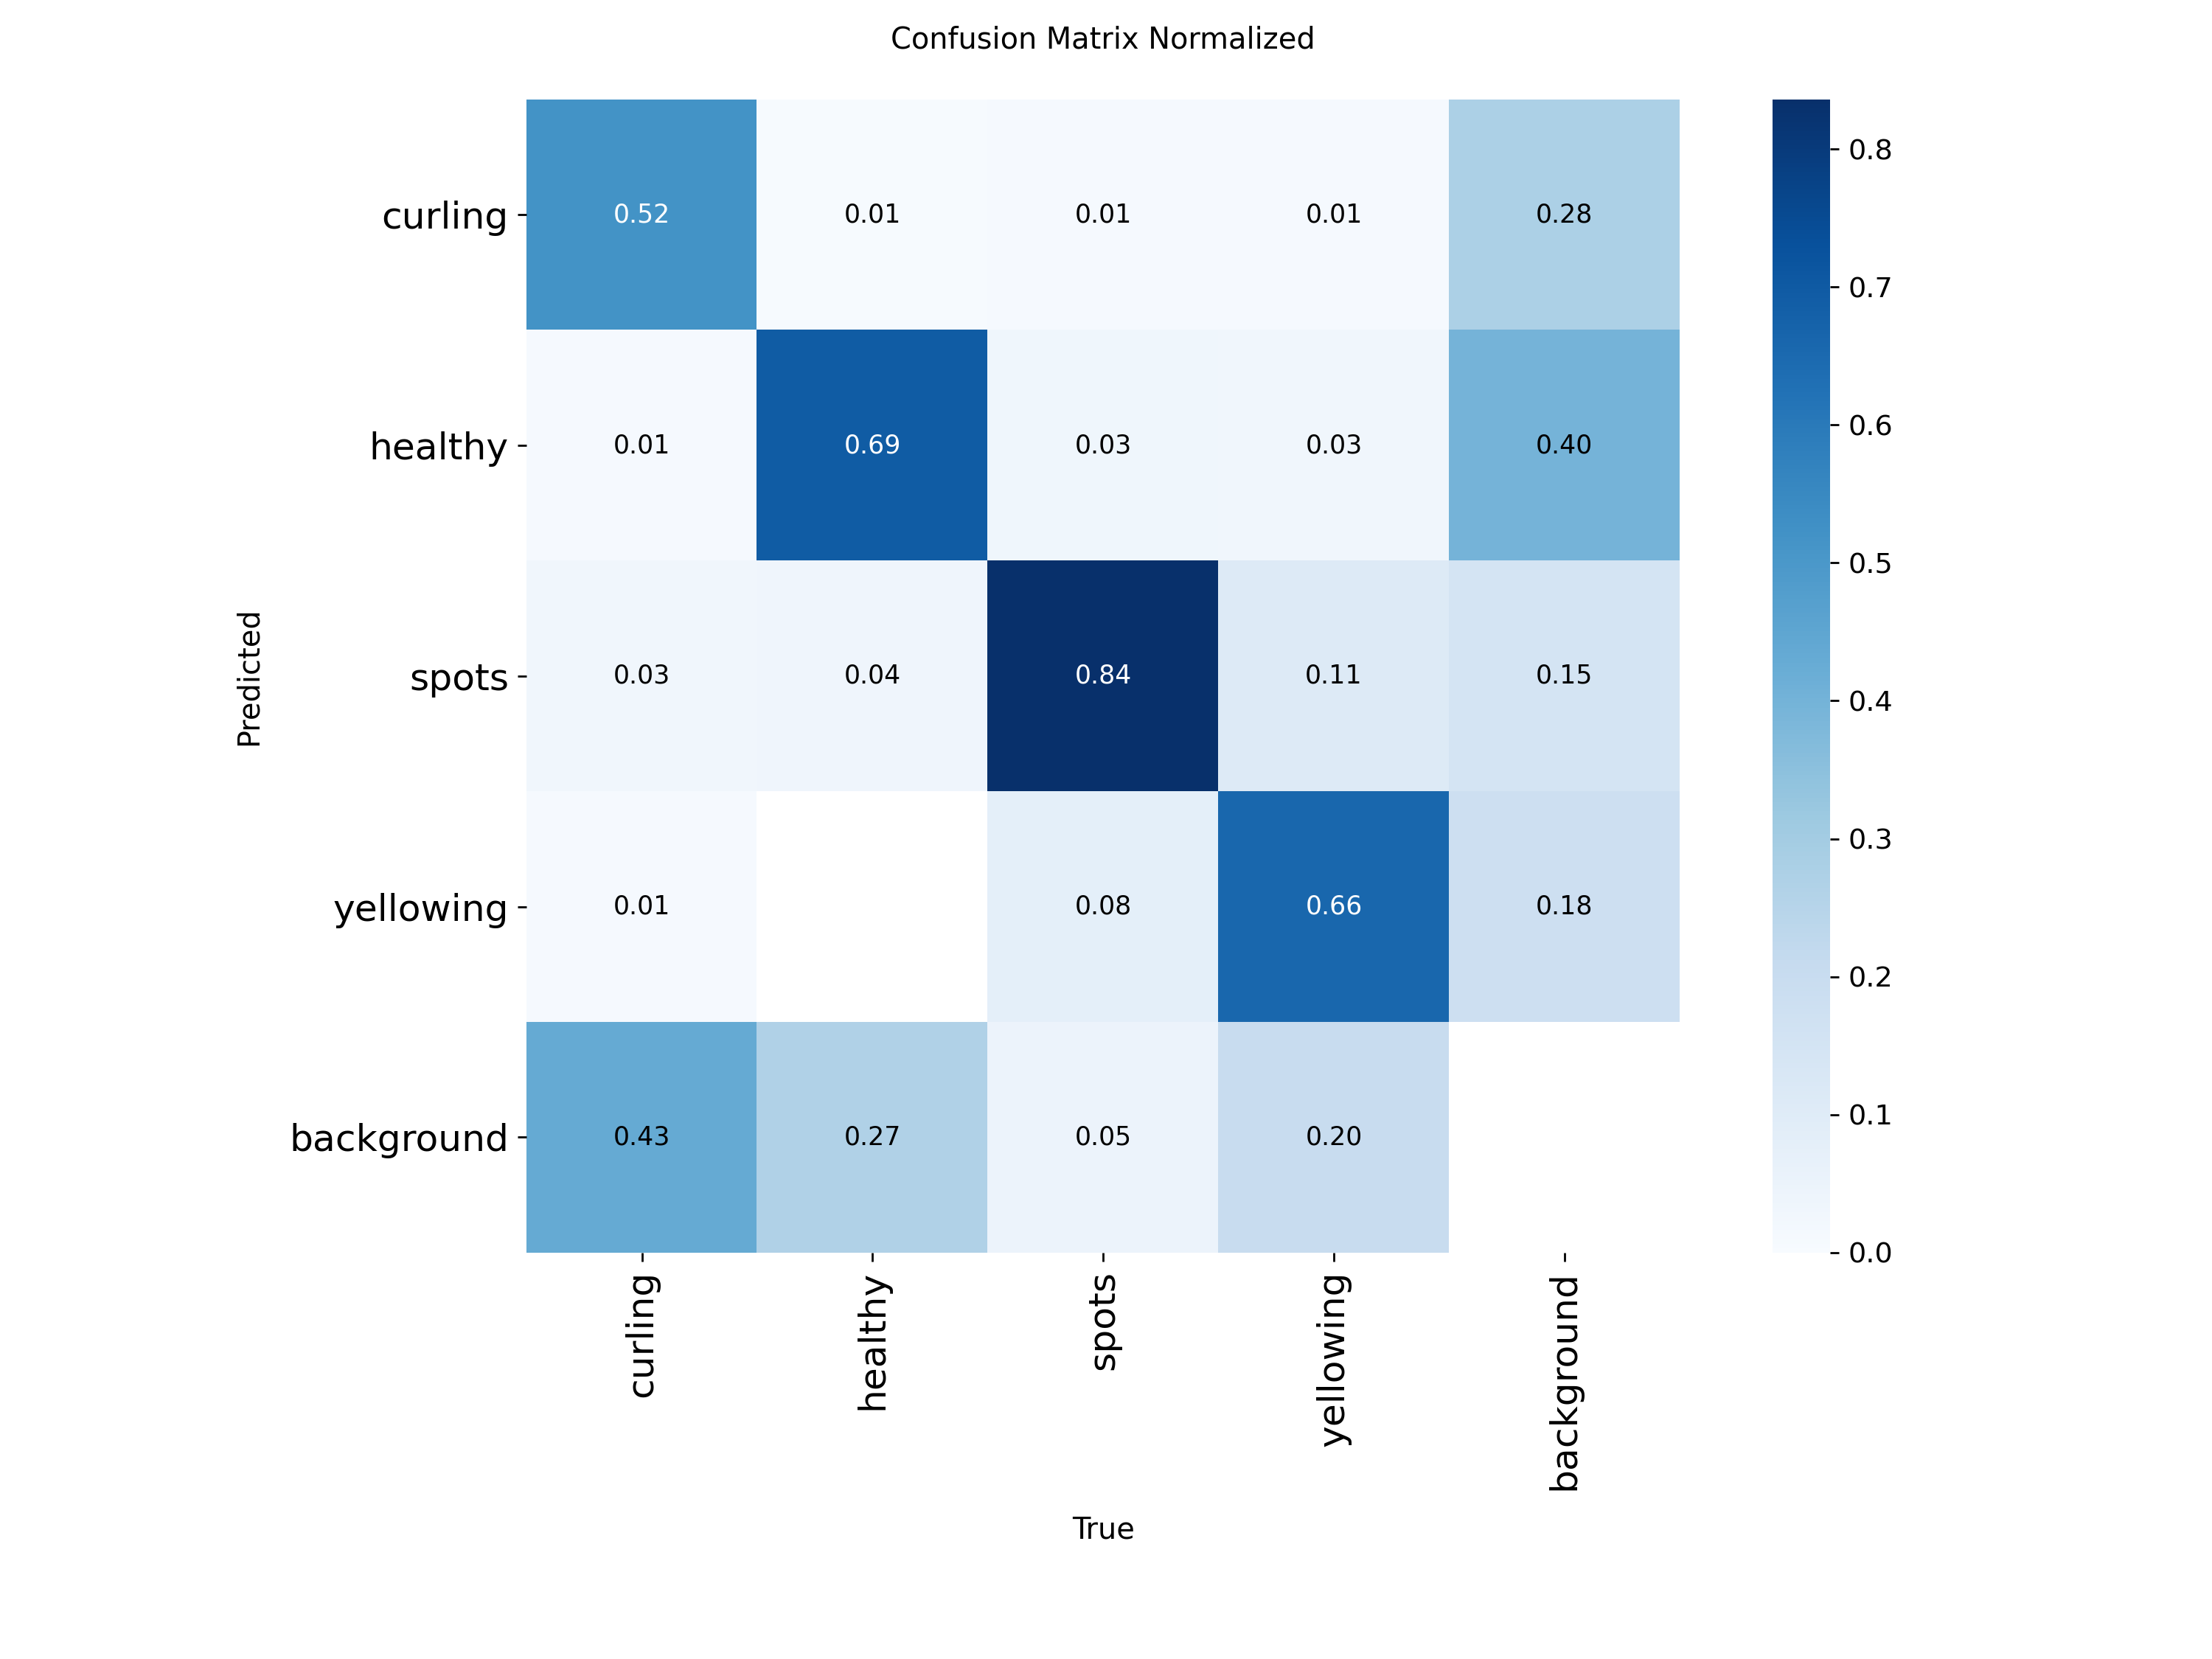

In [ ]:
# ============================================================
# TEST SET EVALUATION & METRICS REPORT
# ============================================================
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display
from ultralytics import YOLO

# 1. Locate the best model weights
eval_weights = Path(PROJECT_DIR) / RUN_NAME / "weights" / "best.pt"
if not eval_weights.exists():
    eval_weights = Path(FINAL_MODEL_SAVE_PATH) / "best.pt"
if not eval_weights.exists():
    eval_weights = Path(FINAL_MODEL_SAVE_PATH)  # In case FINAL_MODEL_SAVE_PATH is best.pt directly

print(f"Loading weights from: {eval_weights}")
trained_model = YOLO(str(eval_weights))

# 2. Run evaluation on the test split
TEST_RUN_NAME = f"{RUN_NAME}_test_eval"
test_metrics = trained_model.val(
    data=DATASET_ROOT,
    split="test",
    project=PROJECT_DIR,
    name=TEST_RUN_NAME,
    plots=True,
    exist_ok=True,
    conf=0.5
)

# 3. Extract Confusion Matrix & calculate metrics
cm = test_metrics.confusion_matrix.matrix  # Shape: (nc + 1, nc + 1)
class_names = list(test_metrics.names.values())
nc = len(class_names)

# Restrict to target classes (excluding background column/row for true target accuracy)
cm_classes = cm[:nc, :nc]
total_targets = cm_classes.sum()
correct_targets = np.trace(cm_classes)

# Overall Accuracy across target instances
overall_accuracy = (correct_targets / total_targets) if total_targets > 0 else 0.0

# Extract Mask Precision, Recall, and calculate F1-score per class
p_per_class = test_metrics.seg.p
r_per_class = test_metrics.seg.r
f1_per_class = [
    (2 * p * r) / (p + r) if (p + r) > 0 else 0.0
    for p, r in zip(p_per_class, r_per_class)
]

# Overall averages
mean_precision = float(np.mean(p_per_class)) if len(p_per_class) else 0.0
mean_recall = float(np.mean(r_per_class)) if len(r_per_class) else 0.0
mean_f1 = (2 * mean_precision * mean_recall) / (mean_precision + mean_recall) if (mean_precision + mean_recall) > 0 else 0.0

# 4. Create and display metrics DataFrame
report_df = pd.DataFrame({
    "Class": class_names,
    "Precision (Mask)": np.round(p_per_class, 4),
    "Recall (Mask)": np.round(r_per_class, 4),
    "F1-Score (Mask)": np.round(f1_per_class, 4)
})

# Add overall summary row
overall_row = pd.DataFrame([{
    "Class": "OVERALL (Mean)",
    "Precision (Mask)": round(mean_precision, 4),
    "Recall (Mask)": round(mean_recall, 4),
    "F1-Score (Mask)": round(mean_f1, 4)
}])
report_df = pd.concat([report_df, overall_row], ignore_index=True)

print("=" * 60)
print(f"TEST SET EVALUATION SUMMARY (Accuracy: {overall_accuracy * 100:.2f}%)")
print("=" * 60)
print(report_df.to_string(index=False))
print(f"\nOverall Target Accuracy : {overall_accuracy:.4f}")
print(f"Overall Mean Precision  : {mean_precision:.4f}")
print(f"Overall Mean Recall     : {mean_recall:.4f}")
print(f"Overall Mean F1-Score   : {mean_f1:.4f}")
print("=" * 60)

# 5. Save tabular results inside PROJECT_DIR
eval_output_dir = Path(PROJECT_DIR) / TEST_RUN_NAME
eval_output_dir.mkdir(parents=True, exist_ok=True)
csv_save_path = eval_output_dir / "test_classification_report.csv"
report_df.to_csv(csv_save_path, index=False)
print(f"Detailed classification report saved to: {csv_save_path}")

# 6. Display Confusion Matrix plot saved by Ultralytics
cm_plot_path = eval_output_dir / "confusion_matrix_normalized.png"
if cm_plot_path.exists():
    print(f"\nDisplaying Normalized Confusion Matrix ({cm_plot_path}):")
    display(Image(filename=str(cm_plot_path)))

Loading weights from: /content/drive/MyDrive/siliguide_yolo_colab/sili_with_null_fix_run1/siliguide_seg_colab_run2/weights/best.pt
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-seg summary (fused): 137 layers, 2,704,512 parameters, 0 gradients, 9.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4109.7±908.5 MB/s, size: 906.7 KB)
val: Scanning /content/sili_with_null_fix4-3/test/labels.cache... 448 images, 88 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 448/448 156.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 28/28 1.3it/s 21.5s
                   all        448        610      0.716      0.679      0.602      0.556      0.716      0.679      0.602      0.583
               curling         54        106      0.632      0.519      0.417      0.375      0.632      0.519      0.417      0.393
               healthy      

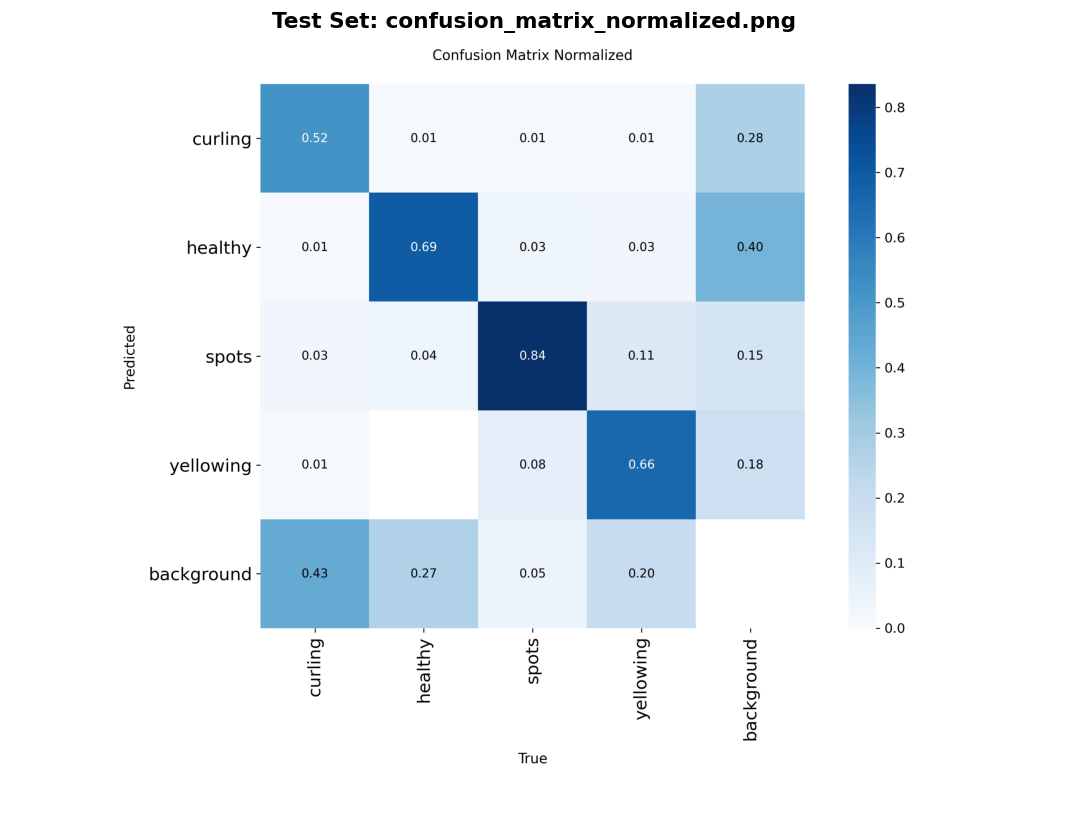

In [ ]:
# ============================================================
# EVALUATION ON HELD-OUT TEST SET
# ============================================================
import os
import sys
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
import torch
from ultralytics import YOLO

# 1. Locate the best model weights
eval_weights = Path(PROJECT_DIR) / RUN_NAME / "weights" / "best.pt"
if not eval_weights.exists():
    eval_weights = Path(FINAL_MODEL_SAVE_PATH) / "best.pt"
if not eval_weights.exists():
    eval_weights = Path(FINAL_MODEL_SAVE_PATH)  # In case FINAL_MODEL_SAVE_PATH is best.pt directly

print(f"Loading weights from: {eval_weights}")
trained_model = YOLO(str(eval_weights))

# 2. Run evaluation on the test split
TEST_RUN_NAME = f"{RUN_NAME}_test_eval"
test_metrics = trained_model.val(
    data=DATASET_ROOT,
    split="test",
    project=PROJECT_DIR,
    name=TEST_RUN_NAME,
    plots=True,
    exist_ok=True,
    conf=0.5
)

# 3. Extract Precision, Recall, F1-Score, and Accuracy
# Mask (Segmentation) metrics
mask_p = float(test_metrics.seg.mp)
mask_r = float(test_metrics.seg.mr)
mask_f1 = (2 * mask_p * mask_r / (mask_p + mask_r + 1e-9)) if (mask_p + mask_r) > 0 else 0.0
mask_map50 = float(test_metrics.seg.map50)
mask_map = float(test_metrics.seg.map)

# Box (Detection) metrics
box_p = float(test_metrics.box.mp)
box_r = float(test_metrics.box.mr)
box_f1 = (2 * box_p * box_r / (box_p + box_r + 1e-9)) if (box_p + box_r) > 0 else 0.0
box_map50 = float(test_metrics.box.map50)
box_map = float(test_metrics.box.map)

# Confusion matrix & Accuracy calculations
cm_obj = getattr(test_metrics, 'confusion_matrix', None)
cm_matrix = cm_obj.matrix if cm_obj is not None else None
names = test_metrics.names
nc = len(names)

if cm_matrix is not None:
    # Classification accuracy on detected instances
    detected_total = np.sum(cm_matrix[:nc, :nc])
    detected_correct = np.trace(cm_matrix[:nc, :nc])
    cls_accuracy = (detected_correct / detected_total) if detected_total > 0 else 0.0

    # Overall accuracy including background false positives / false negatives
    total_preds = np.sum(cm_matrix)
    overall_accuracy = (np.trace(cm_matrix) / total_preds) if total_preds > 0 else 0.0
else:
    cls_accuracy = 0.0
    overall_accuracy = 0.0

# 4. Print Overall Results Summary
print('\n' + '=' * 65)
print('            TEST SET EVALUATION RESULTS SUMMARY')
print('=' * 65)
print(f'Classification Accuracy (Detected Objects) : {cls_accuracy:.4f} ({cls_accuracy:.2%})')
print(f'Overall Accuracy (Including Background)     : {overall_accuracy:.4f} ({overall_accuracy:.2%})')
print('-' * 65)
print(f'Mask Precision (P)                         : {mask_p:.4f}')
print(f'Mask Recall (R)                            : {mask_r:.4f}')
print(f'Mask F1-Score                              : {mask_f1:.4f}')
print(f'Mask mAP @ 0.50                            : {mask_map50:.4f}')
print(f'Mask mAP @ 0.50:0.95                       : {mask_map:.4f}')
print('-' * 65)
print(f'Box Precision (P)                          : {box_p:.4f}')
print(f'Box Recall (R)                             : {box_r:.4f}')
print(f'Box F1-Score                               : {box_f1:.4f}')
print(f'Box mAP @ 0.50                             : {box_map50:.4f}')
print(f'Box mAP @ 0.50:0.95                        : {box_map:.4f}')
print('=' * 65)

# 5. Per-Class Metrics Tables (Mask & Box)

# --- MASK TABLE ---
per_class_mask_data = []
for cid in range(nc):
    cname = names[cid]
    p_c = float(test_metrics.seg.p[cid]) if hasattr(test_metrics.seg, 'p') and len(test_metrics.seg.p) > cid else mask_p
    r_c = float(test_metrics.seg.r[cid]) if hasattr(test_metrics.seg, 'r') and len(test_metrics.seg.r) > cid else mask_r
    f1_c = (2 * p_c * r_c / (p_c + r_c + 1e-9)) if (p_c + r_c) > 0 else 0.0
    map_c = float(test_metrics.seg.maps[cid]) if hasattr(test_metrics.seg, 'maps') and len(test_metrics.seg.maps) > cid else 0.0
    per_class_mask_data.append({
        'Class ID': cid,
        'Class Name': cname,
        'Precision': round(p_c, 4),
        'Recall': round(r_c, 4),
        'F1-Score': round(f1_c, 4),
        'Mask mAP50-95': round(map_c, 4)
    })

df_mask = pd.DataFrame(per_class_mask_data)
print('\n--- PER-CLASS PERFORMANCE BREAKDOWN (MASK) ---')
print(df_mask.to_string(index=False))

# --- BOX TABLE ---
per_class_box_data = []
for cid in range(nc):
    cname = names[cid]
    p_b = float(test_metrics.box.p[cid]) if hasattr(test_metrics.box, 'p') and len(test_metrics.box.p) > cid else box_p
    r_b = float(test_metrics.box.r[cid]) if hasattr(test_metrics.box, 'r') and len(test_metrics.box.r) > cid else box_r
    f1_b = (2 * p_b * r_b / (p_b + r_b + 1e-9)) if (p_b + r_b) > 0 else 0.0
    map_b = float(test_metrics.box.maps[cid]) if hasattr(test_metrics.box, 'maps') and len(test_metrics.box.maps) > cid else 0.0
    per_class_box_data.append({
        'Class ID': cid,
        'Class Name': cname,
        'Precision': round(p_b, 4),
        'Recall': round(r_b, 4),
        'F1-Score': round(f1_b, 4),
        'Box mAP50-95': round(map_b, 4)
    })

df_box = pd.DataFrame(per_class_box_data)
print('\n--- PER-CLASS PERFORMANCE BREAKDOWN (BOX) ---')
print(df_box.to_string(index=False))

# 6. THESIS / PROFESSOR FORMAT: EXACT CONFUSION MATRIX CALCULATION TABLE
if cm_matrix is not None:
    cm = cm_matrix
    rows_thesis = []
    p_list, r_list, f1_list = [], [], []

    for i in range(nc):
        cname = names[i]
        tp = cm[i, i]
        fp = np.sum(cm[:, i]) - tp
        fn = np.sum(cm[i, :]) - tp

        prec = (tp / (tp + fp)) if (tp + fp) > 0 else 0.0
        rec = (tp / (tp + fn)) if (tp + fn) > 0 else 0.0
        f1 = (2 * prec * rec / (prec + rec)) if (prec + rec) > 0 else 0.0

        p_list.append(prec)
        r_list.append(rec)
        f1_list.append(f1)

        rows_thesis.append({
            'Leaf Condition Class': cname.capitalize() if isinstance(cname, str) else f'Class {cname}',
            'Precision': f'{prec:.2%}',
            'Recall': f'{rec:.2%}',
            'F1': f'{f1:.2%}'
        })

    # Macro-average for All Classes
    avg_prec = np.mean(p_list)
    avg_rec = np.mean(r_list)
    avg_f1 = np.mean(f1_list)

    rows_thesis.append({
        'Leaf Condition Class': 'All Classes',
        'Precision': f'{avg_prec:.2%}',
        'Recall': f'{avg_rec:.2%}',
        'F1': f'{avg_f1:.2%}'
    })

    df_thesis = pd.DataFrame(rows_thesis)
    correct_all = int(np.trace(cm))
    total_all = int(np.sum(cm))
    overall_acc = (correct_all / total_all) if total_all > 0 else 0.0

    print('\n' + '=' * 60)
    print('   THESIS EVALUATION TABLE (COMPUTED FROM CONFUSION MATRIX)')
    print('=' * 60)
    print(df_thesis.to_string(index=False))
    print('-' * 60)
    print(f'Overall Accuracy          {overall_acc:.2%} ({correct_all} / {total_all})')
    print('=' * 60)

# 7. Confusion Matrix Table & Plot
if cm_matrix is not None:
    labels = [names[i] for i in range(nc)] + ['background']
    df_cm = pd.DataFrame(cm_matrix.astype(int), index=labels, columns=labels)
    print('\n--- CONFUSION MATRIX (COUNTS) ---')
    print(df_cm)

    save_dir = Path(test_metrics.save_dir)
    cm_files = [save_dir / 'confusion_matrix_normalized.png', save_dir / 'confusion_matrix.png']
    for cm_file in cm_files:
        if cm_file.exists():
            cm_img = Image.open(cm_file)
            plt.figure(figsize=(9, 7), dpi=120)
            plt.imshow(cm_img)
            plt.title(f'Test Set: {cm_file.name}', fontsize=13, fontweight='bold')
            plt.axis('off')
            plt.tight_layout()
            plt.show()
            break


In [ ]:
from ultralytics import YOLO
from pathlib import Path
import shutil

# Load trained model
model = YOLO(FINAL_MODEL_SAVE_PATH)

# Export to TFLite
exported_path = model.export(
    format="tflite",
    imgsz=640,
    nms=True
)

# Get the directory containing best.pt
MODEL_SAVE_DIR = Path(FINAL_MODEL_SAVE_PATH).parent

# # Check whether the model is already in the destination
# if exported_path.resolve().parent == MODEL_SAVE_DIR.resolve():
#     print("TFLite model is already saved in the target directory.")

# elif exported_path.is_file():
#     import shutil
#     shutil.copy2(exported_path, MODEL_SAVE_DIR)

# else:
#     print("Exported model path does not exist:", exported_path)

WARNING ⚠️ format='tflite' is deprecated as of 8.4.83 and has been replaced by the unified Google LiteRT format. Exporting format='litert' instead. See https://docs.ultralytics.com/integrations/litert
Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
WARNING ⚠️ format=litert does not support embedded NMS; exporting native outputs for external NMS.
YOLO26n-seg summary (fused): 137 layers, 2,704,512 parameters, 0 gradients, 9.1 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/siliguide_yolo_colab/SiliGuide_Weights/sili_with_null_fix_run1/best_yolo26_seg.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) ((1, 40, 8400), (1, 32, 160, 160)) (6.3 MB)

LiteRT: starting export with litert_torch 0.10.0...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:02) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


(00:06) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions (+00:04)

... (19 outputs left out)

(00:17) [ DONE] LiteRT-Torch Convert (+00:17)

(00:00) [START] Write Model to 
/content/drive/MyDrive/siliguide_yolo_colab/SiliGuide_Weights/sili_with_null_fix_run1/best_yolo26_seg.tflite

(00:00) [ DONE] Write Model to 
/content/drive/MyDrive/siliguide_yolo_colab/SiliGuide_Weights/sili_with_null_fix_run1/best_yolo26_seg.tflite 
(+00:00)

LiteRT: export success ✅ 17.8s, saved as '/content/drive/MyDrive/siliguide_yolo_colab/SiliGuide_Weights/sili_with_null_fix_run1/best_yolo26_seg.tflite' (10.7 MB)

Export complete (18.7s)
Results saved to /content/drive/MyDrive/siliguide_yolo_colab/SiliGuide_Weights/sili_with_null_fix_run1/best_yolo26_seg.tflite
Predict:         yolo predict task=segment model=/content/drive/MyDrive/siliguide_yolo_colab/SiliGuide_Weights/sili_with_null_fix_run1/best_yolo26_seg.tflite imgsz=640 
Validate:        yolo val task=segment model=/content/drive/MyDrive/siliguide_yolo_colab/SiliGuide_Weights/sili_with_null_fix_run1/best_yolo26_seg.tflite imgsz=640 data=/content/sili_with_null_fix4-3/data.yaml 
Visualize:       https://netron.app
